In [1]:
# Preparar el proyecto en Google Colab o en un entorno local.
import os
import glob
import zipfile
import sys

# En Colab se usa /content; localmente se toma la carpeta que contiene este notebook.
if os.path.isdir("/content"):
    BASE_TRABAJO = "/content"
else:
    BASE_TRABAJO = os.getcwd()

RUTA_PROYECTO = os.path.join(BASE_TRABAJO, "Transforma-Tec")

# El ZIP oficial generado para esta versión se llama Transforma-Tec_Colab_actualizado.zip.
archivos_zip = glob.glob(os.path.join(BASE_TRABAJO, "Transforma-Tec_Colab_actualizado.zip"))
if not os.path.isdir(os.path.join(RUTA_PROYECTO, "src")) and archivos_zip:
    with zipfile.ZipFile(archivos_zip[0], "r") as z:
        z.extractall(BASE_TRABAJO)

if not os.path.isdir(os.path.join(RUTA_PROYECTO, "src")):
    # Si el notebook está dentro de la carpeta del proyecto, usar su directorio padre.
    candidato = os.path.abspath(os.getcwd())
    if os.path.isdir(os.path.join(candidato, "src")):
        RUTA_PROYECTO = candidato
    else:
        raise FileNotFoundError(
            "No encuentro Transforma-Tec/src. En Colab, sube Transforma-Tec_Colab_actualizado.zip a /content y vuelve a ejecutar esta celda."
        )

print("Proyecto encontrado:", RUTA_PROYECTO)


Proyecto encontrado: /content/Transforma-Tec


In [2]:
# Recargar los módulos del proyecto para evitar imports antiguos en Colab.
import sys
import importlib

if RUTA_PROYECTO not in sys.path:
    sys.path.insert(0, RUTA_PROYECTO)

# Si ya se había importado una versión anterior, retirarla de la memoria.
for nombre_modulo in list(sys.modules):
    if nombre_modulo == "src" or nombre_modulo.startswith("src."):
        del sys.modules[nombre_modulo]
importlib.invalidate_caches()

from src.vectores import sumar_vectores, norma_vector
from src.matrices import determinante_matriz
from src.sistemas import resolver_sistema
from src.transformaciones import matriz_rotacion
from src.espacios_vectoriales import calcular_dimension
from src.gamificacion import (
    generar_retos, evaluar_reto, PartidaGamificada, iniciar_juego
)

print("Todos los módulos fueron importados correctamente.")
print("Gamificación:", generar_retos.__name__, evaluar_reto.__name__, PartidaGamificada.__name__, iniciar_juego.__name__)


Todos los módulos fueron importados correctamente.
Gamificación: generar_retos evaluar_reto PartidaGamificada iniciar_juego


In [3]:
import os
import subprocess
import sys

os.chdir(RUTA_PROYECTO)
pruebas = [
    "test_vectores.py",
    "test_matrices.py",
    "test_sistemas.py",
    "test_transformaciones.py",
    "test_espacios_vectoriales.py",
    "test_gamificacion.py",
    "test_aplicaciones.py",
]

for prueba in pruebas:
    print(f"\n===== Ejecutando {prueba} =====")
    resultado = subprocess.run([sys.executable, prueba], text=True)
    if resultado.returncode != 0:
        raise RuntimeError(f"La prueba {prueba} presentó errores.")

print("\nTodas las pruebas finalizaron correctamente.")



===== Ejecutando test_vectores.py =====


Todas las pruebas de vectores fueron exitosas.

===== Ejecutando test_matrices.py =====


Todas las pruebas de matrices fueron exitosas.

===== Ejecutando test_sistemas.py =====


Todas las pruebas de sistemas fueron exitosas.



===== Ejecutando test_transformaciones.py =====


Todas las pruebas de transformaciones fueron exitosas.


... (3 outputs left out)

Todas las pruebas del sistema de gamificación fueron exitosas.
15 retos reproducibles, evaluación, vidas, puntaje, insignias y desbloqueo verificados.



===== Ejecutando test_aplicaciones.py =====


Todas las pruebas de aplicaciones fueron exitosas.



Todas las pruebas finalizaron correctamente.


# TRANSFORMA-TEC: EL GRAN RETO FINAL

**Universidad de Santander (UDES)**  
**Programa:** Ingeniería de Software  
**Asignatura:** Álgebra Lineal  

**Integrantes:**
- Nicolás Muskus Tarazona
- Danilo Muskus Tarazona

**Docente:** Islenis Carolina Botello Cuvides

## Introducción

Transforma-Tec es un proyecto académico que integra los fundamentos del álgebra lineal con herramientas de programación en Python. Mediante el uso de NumPy y Matplotlib, se desarrollan operaciones matemáticas, soluciones de sistemas de ecuaciones, transformaciones lineales y análisis de espacios vectoriales.

El proyecto busca demostrar cómo los conceptos del álgebra lineal pueden aplicarse a problemas computacionales mediante módulos reutilizables, representaciones gráficas y actividades de aprendizaje interactivas.

## Objetivo general

Desarrollar una herramienta computacional que permita comprender, aplicar y visualizar conceptos fundamentales del álgebra lineal mediante Python.

## Tecnologías utilizadas

- Python.
- NumPy.
- Matplotlib.
- Google Colab.
- Git y GitHub.
- GeoGebra.

# 1. Operaciones con vectores

## Fundamento teórico

Un vector es un objeto matemático que posee magnitud, dirección y sentido. En el plano cartesiano puede representarse mediante dos componentes, mientras que en el espacio tridimensional utiliza tres componentes.

Entre las operaciones fundamentales se encuentran:

- **Suma:** combina dos vectores componente a componente.
- **Norma:** calcula la magnitud o longitud de un vector.
- **Producto punto:** permite obtener un escalar a partir de dos vectores.
- **Producto cruz:** genera un vector perpendicular a otros dos vectores tridimensionales.

Estas operaciones tienen aplicaciones en gráficos por computadora, simulaciones físicas y procesamiento de datos.

VECTOR A: [3 4]
VECTOR B: [-2  3]
Suma de vectores: [1. 7.]
Norma del vector A: 5.0


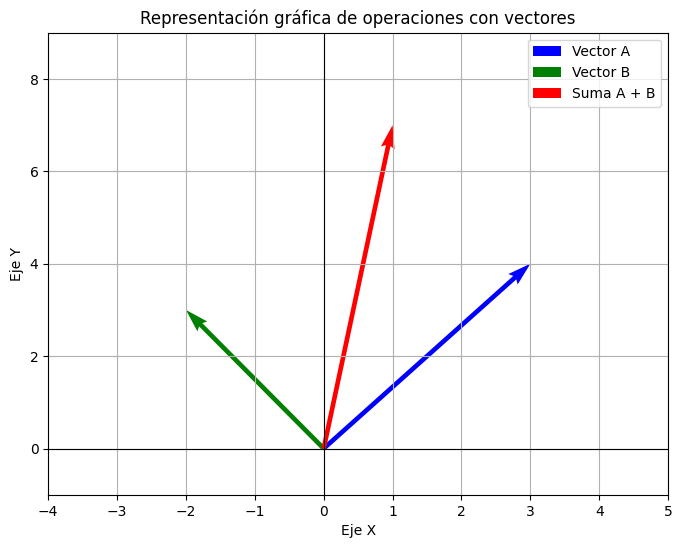

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Definición de vectores
vector_a = np.array([3, 4])
vector_b = np.array([-2, 3])

# Operaciones
resultado_suma = sumar_vectores(vector_a, vector_b)
magnitud_a = norma_vector(vector_a)

print("VECTOR A:", vector_a)
print("VECTOR B:", vector_b)
print("Suma de vectores:", resultado_suma)
print("Norma del vector A:", magnitud_a)

# Representación gráfica
plt.figure(figsize=(8, 6))

plt.quiver(0, 0, vector_a[0], vector_a[1],
           angles="xy", scale_units="xy", scale=1,
           color="blue", label="Vector A")

plt.quiver(0, 0, vector_b[0], vector_b[1],
           angles="xy", scale_units="xy", scale=1,
           color="green", label="Vector B")

plt.quiver(0, 0, resultado_suma[0], resultado_suma[1],
           angles="xy", scale_units="xy", scale=1,
           color="red", label="Suma A + B")

plt.xlim(-4, 5)
plt.ylim(-1, 9)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(True)
plt.legend()
plt.title("Representación gráfica de operaciones con vectores")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.show()

# 2. Operaciones con matrices

## Fundamento teórico

Una matriz es un arreglo rectangular de números organizado en filas y columnas. Se utiliza para representar datos, resolver sistemas de ecuaciones y realizar transformaciones lineales.

Entre sus operaciones principales se encuentran:

- **Suma:** se suman los elementos que ocupan la misma posición.
- **Multiplicación:** combina filas de la primera matriz con columnas de la segunda.
- **Determinante:** es un valor escalar asociado a una matriz cuadrada.
- **Matriz inversa:** es aquella que, al multiplicarse por la matriz original, produce la matriz identidad. Existe cuando el determinante es diferente de cero.

Matriz A:
 [[2 1]
 [3 4]]

Matriz B:
 [[1 2]
 [0 3]]

Suma:
 [[3. 3.]
 [3. 7.]]

Producto A x B:
 [[ 2.  7.]
 [ 3. 18.]]

Determinante de A: 5.000000000000001

Inversa de A:
 [[ 0.8 -0.2]
 [-0.6  0.4]]


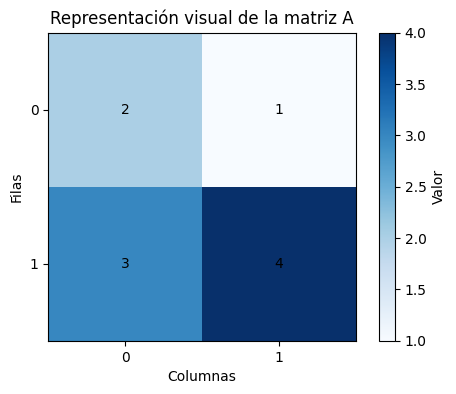

In [5]:
from src.matrices import (
    sumar_matrices,
    multiplicar_matrices,
    determinante_matriz,
    inversa_matriz
)

# Definición de matrices
matriz_a = np.array([
    [2, 1],
    [3, 4]
])

matriz_b = np.array([
    [1, 2],
    [0, 3]
])

# Operaciones
suma = sumar_matrices(matriz_a, matriz_b)
producto = multiplicar_matrices(matriz_a, matriz_b)
determinante = determinante_matriz(matriz_a)
inversa = inversa_matriz(matriz_a)

print("Matriz A:\n", matriz_a)
print("\nMatriz B:\n", matriz_b)
print("\nSuma:\n", suma)
print("\nProducto A x B:\n", producto)
print("\nDeterminante de A:", determinante)
print("\nInversa de A:\n", inversa)

# Visualización
plt.figure(figsize=(6, 4))
plt.imshow(matriz_a, cmap="Blues")
plt.colorbar(label="Valor")
plt.title("Representación visual de la matriz A")
plt.xlabel("Columnas")
plt.ylabel("Filas")
plt.xticks([0, 1])
plt.yticks([0, 1])

for i in range(2):
    for j in range(2):
        plt.text(j, i, matriz_a[i, j],
                 ha="center", va="center", color="black")

plt.show()

# 3. Sistemas de ecuaciones lineales

## Fundamento teórico

Un sistema de ecuaciones lineales está formado por dos o más ecuaciones que comparten un conjunto de incógnitas.

Puede representarse mediante la expresión matricial:

\[
AX=B
\]

Donde:

- **A:** matriz de coeficientes.
- **X:** vector de incógnitas.
- **B:** vector de términos independientes.

Entre los métodos para resolver estos sistemas se encuentra la eliminación de Gauss, que permite transformar el sistema en una forma más sencilla para encontrar sus soluciones.

Según sus características, un sistema puede tener una solución única, infinitas soluciones o ninguna solución.

In [6]:
from src.sistemas import (
    resolver_sistema,
    eliminacion_gauss
)

# Sistema:
# 2x + y = 5
# x + 3y = 7

A = np.array([
    [2, 1],
    [1, 3]
], dtype=float)

B = np.array([5, 7], dtype=float)

# Resolver sistema
solucion = resolver_sistema(A, B)

# Aplicar eliminación de Gauss
matriz_escalonada = eliminacion_gauss(A, B)

print("Matriz de coeficientes:")
print(A)

print("\nVector independiente:")
print(B)

print("\nSolución del sistema:")
print("x =", solucion.solucion[0])
print("y =", solucion.solucion[1])

print("\nSolución obtenida mediante eliminación de Gauss:")
print(matriz_escalonada.matriz_escalonada)

# Verificación
verificacion = np.allclose(A @ solucion.solucion, B)
print("\n¿La solución satisface el sistema?", verificacion)

Matriz de coeficientes:
[[2. 1.]
 [1. 3.]]

Vector independiente:
[5. 7.]

Solución del sistema:
x = 1.6
y = 1.8

Solución obtenida mediante eliminación de Gauss:
[[2.  1.  5. ]
 [0.  2.5 4.5]]

¿La solución satisface el sistema? True


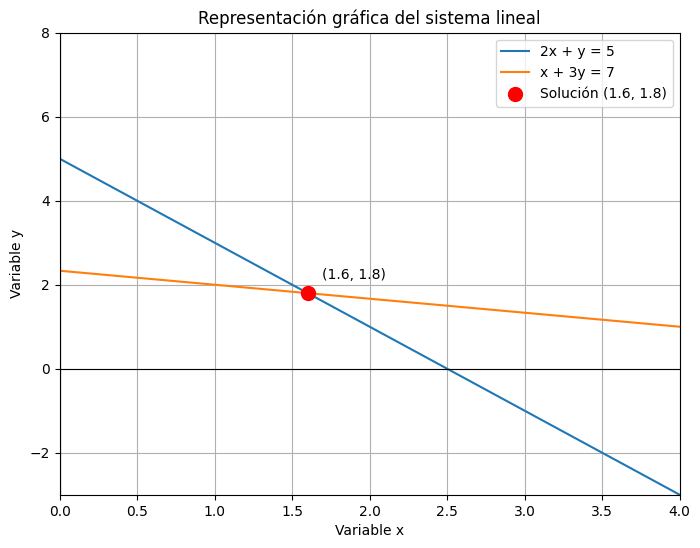

In [7]:
# Representación gráfica del sistema de ecuaciones

x = np.linspace(0, 4, 100)

# Ecuación 1: 2x + y = 5
y1 = 5 - 2*x

# Ecuación 2: x + 3y = 7
y2 = (7 - x) / 3

plt.figure(figsize=(8, 6))

plt.plot(x, y1, label="2x + y = 5")
plt.plot(x, y2, label="x + 3y = 7")

# Punto de intersección
plt.scatter(solucion.solucion[0], solucion.solucion[1],
            color="red", s=100,
            label=f"Solución ({solucion.solucion[0]}, {solucion.solucion[1]})",
            zorder=5)

plt.annotate(
    f"({solucion.solucion[0]}, {solucion.solucion[1]})",
    (solucion.solucion[0], solucion.solucion[1]),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(0, 4)
plt.ylim(-3, 8)
plt.xlabel("Variable x")
plt.ylabel("Variable y")
plt.title("Representación gráfica del sistema lineal")
plt.grid(True)
plt.legend()
plt.show()

## Sistema incompatible (sin solución)

Un sistema es **incompatible** cuando $\operatorname{rango}(A)<\operatorname{rango}([A\,|\,\vec{b}])$ (teorema de Rouché–Frobenius). Al aplicar la eliminación de Gauss aparece una fila de la forma $0=c$ con $c\neq 0$, que es una contradicción.

Se analiza el sistema

$$
\begin{cases}
2x + y = 5\\
4x + 2y = 7
\end{cases}
$$

Las dos ecuaciones tienen la misma pendiente $(-2)$ pero distinta ordenada al origen, de modo que sus rectas son paralelas y no se cortan. Al multiplicar la primera ecuación por 2 se obtiene $4x+2y=10$, que contradice $4x+2y=7$.

Matriz de coeficientes A:
[[2. 1.]
 [4. 2.]]

Vector independiente b:
[5. 7.]

Matriz ampliada tras la eliminación hacia adelante [A | b]:
[[4.  2.  7. ]
 [0.  0.  1.5]]

Clasificación: Incompatible (sin solución)
rango(A) = 1, rango([A|b]) = 2, incógnitas = 2
Tipo: no homogéneo
No existe ningún vector x que satisfaga Ax = b.

Verificación con NumPy: numpy.linalg.solve no aplica (matriz singular o no cuadrada); rango(A) coincide con NumPy: True. Sin solución.
Determinante de A: 0.0


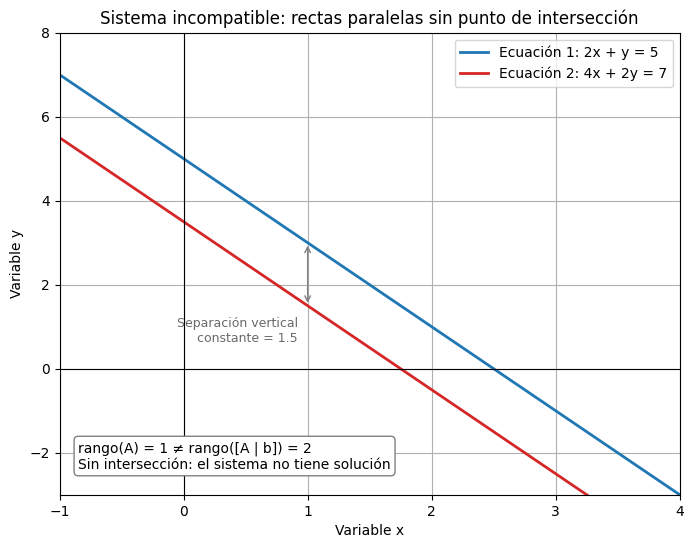

In [8]:
# Sistema incompatible: dos rectas paralelas (sin punto de intersección)
#   2x +  y = 5
#   4x + 2y = 7
from src.sistemas import eliminacion_gauss, comparar_con_numpy, INCOMPATIBLE

A_inc = np.array([
    [2, 1],
    [4, 2]
], dtype=float)

B_inc = np.array([5, 7], dtype=float)

# Eliminación de Gauss y clasificación automática
resultado_inc = eliminacion_gauss(A_inc, B_inc)

print("Matriz de coeficientes A:")
print(A_inc)

print("\nVector independiente b:")
print(B_inc)

print("\nMatriz ampliada tras la eliminación hacia adelante [A | b]:")
print(resultado_inc.matriz_escalonada)

print("\n" + resultado_inc.resumen())

# Verificación con NumPy: A es singular, por lo que linalg.solve no aplica
print("\nVerificación con NumPy:", comparar_con_numpy(A_inc, B_inc)["detalle"])
print("Determinante de A:", round(np.linalg.det(A_inc), 10))

assert resultado_inc.clasificacion == INCOMPATIBLE
assert resultado_inc.rango_A == 1 and resultado_inc.rango_ampliada == 2

# Representación gráfica: las rectas son paralelas y no se cortan
x = np.linspace(-1, 4, 200)
y1 = 5 - 2 * x          # 2x + y = 5
y2 = (7 - 4 * x) / 2    # 4x + 2y = 7

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(x, y1, color="tab:blue", linewidth=2, label="Ecuación 1: 2x + y = 5")
ax.plot(x, y2, color="tab:red", linewidth=2, label="Ecuación 2: 4x + 2y = 7")

# Separación vertical constante entre las rectas (1.5 unidades)
ax.annotate("", xy=(1, 3), xytext=(1, 1.5),
            arrowprops=dict(arrowstyle="<->", color="gray"))
ax.text(0.92, 0.9, "Separación vertical\nconstante = 1.5", fontsize=9,
        color="dimgray", ha="right", va="center")

ax.text(0.03, 0.05,
        "rango(A) = 1 ≠ rango([A | b]) = 2\nSin intersección: el sistema no tiene solución",
        transform=ax.transAxes, fontsize=10, va="bottom",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 4)
ax.set_ylim(-3, 8)
ax.set_xlabel("Variable x")
ax.set_ylabel("Variable y")
ax.set_title("Sistema incompatible: rectas paralelas sin punto de intersección")
ax.grid(True)
ax.legend(loc="upper right")
fig.savefig("figura_sistema_incompatible.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.1 Validación ampliada de Gauss y aplicación en Ingeniería de Software
En esta subsección se amplía la resolución inicial 2×2 con sistemas 3×3 y 4×4, casos homogéneos y no homogéneos, soluciones infinitas, comparación con NumPy y dos modelos aplicados: balance de carga y circulación de tráfico en una red.

La batería utiliza las funciones del módulo `src.sistemas`; no se reemplaza la implementación del proyecto, sino que se valida con escenarios de mayor dimensión.

## Celda A (Markdown) — Sistemas homogéneos y no homogéneos

Un sistema lineal $A\vec{x}=\vec{b}$ es **homogéneo** cuando $\vec{b}=\vec{0}$ y **no homogéneo** cuando $\vec{b}\neq\vec{0}$. Un sistema homogéneo siempre es compatible porque admite la solución trivial $\vec{x}=\vec{0}$; tiene infinitas soluciones únicamente si $\operatorname{rango}(A)<n$.

La función `eliminacion_gauss` clasifica cada caso con los rangos de $A$ y de la matriz ampliada $[A\,|\,\vec{b}]$ (teorema de Rouché–Frobenius) y la función `comparar_con_numpy` contrasta el resultado con `numpy.linalg.solve`.

In [9]:
# Celda B — Batería de pruebas: 2x2, 3x3 y 4x4, homogéneos y no homogéneos
import numpy as np
import matplotlib.pyplot as plt
from src.sistemas import eliminacion_gauss, comparar_con_numpy

casos = [
    ("2x2 no homogéneo", [[2, 1], [1, -1]], [5, 1]),
    ("2x2 homogéneo", [[1, 2], [3, 4]], [0, 0]),
    ("3x3 no homogéneo", [[2, 1, -1], [-3, -1, 2], [-2, 1, 2]], [8, -11, -3]),
    ("3x3 homogéneo (trivial)", [[1, 1, 1], [1, 2, 3], [2, 1, 4]], [0, 0, 0]),
    ("3x3 homogéneo (no trivial)", [[1, 2, 3], [2, 4, 6], [1, 0, 1]], [0, 0, 0]),
    ("3x3 infinitas soluciones", [[1, 1, 1], [1, 2, 3], [2, 3, 4]], [6, 14, 20]),
    ("4x4 no homogéneo", [[1, 1, 1, 1], [2, -1, 0, 3], [0, 1, -1, 2], [3, 0, 2, -1]], [10, 9, 3, 7]),
    ("4x4 homogéneo (no trivial)", [[1, 1, 0, 1], [0, 1, 1, 0], [1, 2, 1, 1], [2, 3, 1, 2]], [0, 0, 0, 0]),
    ("4x4 incompatible", [[1, 1, 0, 0], [0, 1, 1, 0], [0, 0, 1, 1], [1, 2, 2, 1]], [1, 2, 3, 20]),
]

print(f"{'Caso':<28}{'Tipo':<14}{'rg(A)':<7}{'rg(A|b)':<9}{'Clasificación':<26}{'Verif. NumPy'}")
print("-" * 100)
for nombre, A, b in casos:
    r = eliminacion_gauss(A, b)
    cmp = comparar_con_numpy(A, b)
    tipo = "homogéneo" if r.es_homogeneo else "no homogéneo"
    clase = r.clasificacion.split(" (")[0]
    verif = "OK" if cmp["coincide"] else "FALLA"
    if cmp["metodo"] == "numpy.linalg.solve":
        verif += f" (error {cmp['error_maximo']:.1e})"
    else:
        verif += " (rangos)"
    print(f"{nombre:<28}{tipo:<14}{r.rango_A:<7}{r.rango_ampliada:<9}{clase:<26}{verif}")
    assert cmp["coincide"], nombre

Caso                        Tipo          rg(A)  rg(A|b)  Clasificación             Verif. NumPy
----------------------------------------------------------------------------------------------------
2x2 no homogéneo            no homogéneo  2      2        Compatible determinado    OK (error 0.0e+00)
2x2 homogéneo               homogéneo     2      2        Compatible determinado    OK (error 0.0e+00)
3x3 no homogéneo            no homogéneo  3      3        Compatible determinado    OK (error 1.1e-15)
3x3 homogéneo (trivial)     homogéneo     3      3        Compatible determinado    OK (error 0.0e+00)
3x3 homogéneo (no trivial)  homogéneo     2      2        Compatible indeterminado  OK (rangos)
3x3 infinitas soluciones    no homogéneo  2      2        Compatible indeterminado  OK (rangos)
4x4 no homogéneo            no homogéneo  4      4        Compatible determinado    OK (error 4.4e-16)
4x4 homogéneo (no trivial)  homogéneo     2      2        Compatible indeterminado  OK (rangos)

In [10]:
# Celda C — Solución detallada de tres casos representativos
for nombre, A, b in [casos[2], casos[5], casos[7]]:
    print(f"=== {nombre} ===")
    print(eliminacion_gauss(A, b))
    print()

=== 3x3 no homogéneo ===
Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: no homogéneo
x1 = 2
x2 = 3
x3 = -1

=== 3x3 infinitas soluciones ===
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 3
Tipo: no homogéneo
Solución general (1 parámetro(s) libre(s)):
x1 = -2 + t1
x2 = 8 - 2·t1
x3 = t1  (variable libre)

=== 4x4 homogéneo (no trivial) ===
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 4
Tipo: homogéneo
Solución general (2 parámetro(s) libre(s)):
x1 = t1 - t2
x2 = -t1
x3 = t1  (variable libre)
x4 = t2  (variable libre)



## Celda D (Markdown) — Aplicación en Ingeniería de Software: balance de carga

Un balanceador de carga reparte $T$ peticiones por segundo entre $n$ servidores con capacidades relativas $w_1,\dots,w_n$. Sea $x_i$ la carga asignada al servidor $i$. El modelo es:

$$
\begin{cases}
x_1 + x_2 + \cdots + x_n = T & \text{(se atiende toda la demanda)}\\
w_1 x_i - w_i x_1 = 0,\quad i=2,\dots,n & \text{(carga proporcional a la capacidad)}
\end{cases}
$$

Es un sistema no homogéneo $n\times n$ cuyas $n-1$ últimas ecuaciones son homogéneas. Con $T=0$ el sistema completo pasa a ser homogéneo y solo admite la solución trivial (no hay demanda que repartir).

Matriz de coeficientes A:
 [[ 1.  1.  1.]
 [-2.  4.  0.]
 [-5.  0.  4.]]
Vector b: [1100.    0.    0.]

Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: no homogéneo
x1 = 400
x2 = 200
x3 = 500

Servidor  Capacidad  Carga (req/s)  % del total
S1        4          400.0          36.4 %
S2        2          200.0          18.2 %
S3        5          500.0          45.5 %

Verificación contra numpy.linalg.solve: Error máximo |x_Gauss - x_NumPy| = 0.00e+00


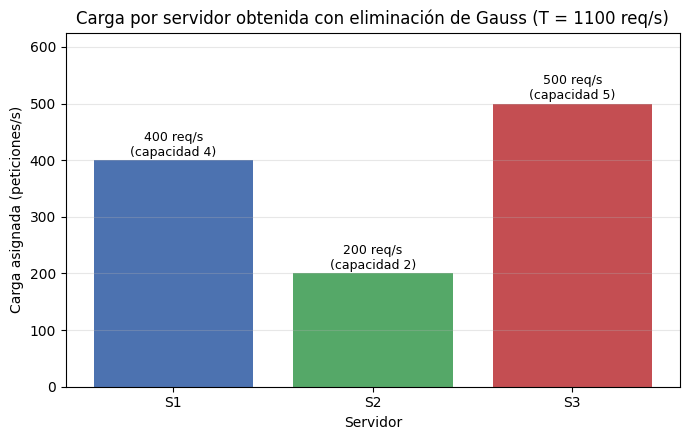

In [11]:
# Celda E — Balance de carga con 3 servidores (capacidades 4, 2 y 5; T = 1100 req/s)
from src.aplicaciones import sistema_balance_carga, balancear_carga

pesos = [4, 2, 5]
total = 1100
A, b = sistema_balance_carga(total, pesos)
resultado = balancear_carga(total, pesos)

print("Matriz de coeficientes A:\n", A)
print("Vector b:", b)
print()
print(resultado)
print()
print(f"{'Servidor':<10}{'Capacidad':<11}{'Carga (req/s)':<15}{'% del total'}")
for i, (w, x) in enumerate(zip(pesos, resultado.solucion), start=1):
    print(f"S{i:<9}{w:<11}{x:<15.1f}{100 * x / total:.1f} %")

cmp = comparar_con_numpy(A, b)
print("\nVerificación contra numpy.linalg.solve:", cmp["detalle"])
assert cmp["coincide"]

fig, ax = plt.subplots(figsize=(7, 4.5))
nombres = [f"S{i}" for i in range(1, len(pesos) + 1)]
barras = ax.bar(nombres, resultado.solucion, color=["#4C72B0", "#55A868", "#C44E52"])
for barra, w in zip(barras, pesos):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 8,
            f"{barra.get_height():.0f} req/s\n(capacidad {w})", ha="center", fontsize=9)
ax.set_xlabel("Servidor")
ax.set_ylabel("Carga asignada (peticiones/s)")
ax.set_title("Carga por servidor obtenida con eliminación de Gauss (T = 1100 req/s)")
ax.set_ylim(0, max(resultado.solucion) * 1.25)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Celda F — Variantes del modelo: 4 servidores, política incompleta y requisitos contradictorios
# (a) 4 servidores (sistema 4x4)
pesos4 = [3, 2, 1, 4]
A4, b4 = sistema_balance_carga(1000, pesos4)
r4 = balancear_carga(1000, pesos4)
print("(a) 4 servidores, capacidades", pesos4)
print(r4)
print("   Verificación NumPy:", comparar_con_numpy(A4, b4)["detalle"])

# (b) Política incompleta: se omite la regla del último servidor -> infinitas soluciones
A_inc, b_inc = A[:-1], b[:-1]
r_inc = eliminacion_gauss(A_inc, b_inc)
print("\n(b) Política incompleta (3 servidores, 2 ecuaciones)")
print(r_inc)
print("   Ejemplo con t1 = 300:", r_inc.solucion_para([300.0]))

# (c) Requisitos contradictorios: se exige además que el total sea 900 req/s
A_con = np.vstack([A, np.ones(3)])
b_con = np.append(b, 900.0)
r_con = eliminacion_gauss(A_con, b_con)
print("\n(c) Requisitos contradictorios (total = 1100 y total = 900)")
print(r_con)

# (d) Sin demanda (sistema homogéneo): solo la solución trivial
print("\n(d) Sin demanda (T = 0)")
print(balancear_carga(0, pesos))

(a) 4 servidores, capacidades [3, 2, 1, 4]
Clasificación: Compatible determinado (solución única)
rango(A) = 4, rango([A|b]) = 4, incógnitas = 4
Tipo: no homogéneo
x1 = 300
x2 = 200
x3 = 100
x4 = 400
   Verificación NumPy: Error máximo |x_Gauss - x_NumPy| = 0.00e+00

(b) Política incompleta (3 servidores, 2 ecuaciones)
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 3
Tipo: no homogéneo
Solución general (1 parámetro(s) libre(s)):
x1 = 2200/3 - 2/3·t1
x2 = 1100/3 - 1/3·t1
x3 = t1  (variable libre)
   Ejemplo con t1 = 300: [533.33333333 266.66666667 300.        ]

(c) Requisitos contradictorios (total = 1100 y total = 900)
Clasificación: Incompatible (sin solución)
rango(A) = 3, rango([A|b]) = 4, incógnitas = 3
Tipo: no homogéneo
No existe ningún vector x que satisfaga Ax = b.

(d) Sin demanda (T = 0)
Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: homogéneo
x1 = 0
x2 =

## Celda G (Markdown) — Sistema homogéneo aplicado: circulación de tráfico en una red

En una red de tres enrutadores sin tráfico externo, el tráfico que entra a cada nodo debe ser igual al que sale. Con los enlaces $f_1:R_1\to R_2$, $f_2:R_2\to R_3$, $f_3:R_3\to R_1$ y $f_4:R_1\to R_3$ se obtiene un sistema **homogéneo** de rango 2 con cuatro incógnitas, por lo que existen infinitas circulaciones posibles:

$$
\begin{cases}
f_3 - f_1 - f_4 = 0 & (R_1)\\
f_1 - f_2 = 0 & (R_2)\\
f_2 + f_4 - f_3 = 0 & (R_3)
\end{cases}
$$

In [13]:
# Celda H — Resolución de la red de enrutadores
from src.aplicaciones import sistema_flujo_red, analizar_flujo_red

A_red, b_red = sistema_flujo_red()
r_red = analizar_flujo_red()
print("Matriz de conservación A:\n", A_red)
print()
print(r_red)
print()
print("Ejemplo físico (t1 = 5, t2 = 2) -> f =", r_red.solucion_para([5, 2]))
print("Comprobación A·f = 0:", np.allclose(A_red @ r_red.solucion_para([5, 2]), 0))
print("Verificación NumPy:", comparar_con_numpy(A_red, b_red)["detalle"])
print("\nNota: para que los flujos sean físicamente válidos (f ≥ 0) se requiere t1 ≥ t2 ≥ 0.")

Matriz de conservación A:
 [[-1.  0.  1. -1.]
 [ 1. -1.  0.  0.]
 [ 0.  1. -1.  1.]]

Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 4
Tipo: homogéneo
Solución general (2 parámetro(s) libre(s)):
x1 = t1 - t2
x2 = t1 - t2
x3 = t1  (variable libre)
x4 = t2  (variable libre)

Ejemplo físico (t1 = 5, t2 = 2) -> f = [3. 3. 5. 2.]
Comprobación A·f = 0: True
Verificación NumPy: numpy.linalg.solve no aplica (matriz singular o no cuadrada); rango(A) coincide con NumPy: True; residuo de la solución = 0.00e+00

Nota: para que los flujos sean físicamente válidos (f ≥ 0) se requiere t1 ≥ t2 ≥ 0.


## Celda A (Markdown) — Sistemas homogéneos y no homogéneos

Un sistema lineal $A\vec{x}=\vec{b}$ es **homogéneo** cuando $\vec{b}=\vec{0}$ y **no homogéneo** cuando $\vec{b}\neq\vec{0}$. Un sistema homogéneo siempre es compatible porque admite la solución trivial $\vec{x}=\vec{0}$; tiene infinitas soluciones únicamente si $\operatorname{rango}(A)<n$.

La función `eliminacion_gauss` clasifica cada caso con los rangos de $A$ y de la matriz ampliada $[A\,|\,\vec{b}]$ (teorema de Rouché–Frobenius) y la función `comparar_con_numpy` contrasta el resultado con `numpy.linalg.solve`.

In [14]:
# Celda B — Batería de pruebas: 2x2, 3x3 y 4x4, homogéneos y no homogéneos
import numpy as np
import matplotlib.pyplot as plt
from src.sistemas import eliminacion_gauss, comparar_con_numpy

casos = [
    ("2x2 no homogéneo", [[2, 1], [1, -1]], [5, 1]),
    ("2x2 homogéneo", [[1, 2], [3, 4]], [0, 0]),
    ("3x3 no homogéneo", [[2, 1, -1], [-3, -1, 2], [-2, 1, 2]], [8, -11, -3]),
    ("3x3 homogéneo (trivial)", [[1, 1, 1], [1, 2, 3], [2, 1, 4]], [0, 0, 0]),
    ("3x3 homogéneo (no trivial)", [[1, 2, 3], [2, 4, 6], [1, 0, 1]], [0, 0, 0]),
    ("3x3 infinitas soluciones", [[1, 1, 1], [1, 2, 3], [2, 3, 4]], [6, 14, 20]),
    ("4x4 no homogéneo", [[1, 1, 1, 1], [2, -1, 0, 3], [0, 1, -1, 2], [3, 0, 2, -1]], [10, 9, 3, 7]),
    ("4x4 homogéneo (no trivial)", [[1, 1, 0, 1], [0, 1, 1, 0], [1, 2, 1, 1], [2, 3, 1, 2]], [0, 0, 0, 0]),
    ("4x4 incompatible", [[1, 1, 0, 0], [0, 1, 1, 0], [0, 0, 1, 1], [1, 2, 2, 1]], [1, 2, 3, 20]),
]

print(f"{'Caso':<28}{'Tipo':<14}{'rg(A)':<7}{'rg(A|b)':<9}{'Clasificación':<26}{'Verif. NumPy'}")
print("-" * 100)
for nombre, A, b in casos:
    r = eliminacion_gauss(A, b)
    cmp = comparar_con_numpy(A, b)
    tipo = "homogéneo" if r.es_homogeneo else "no homogéneo"
    clase = r.clasificacion.split(" (")[0]
    verif = "OK" if cmp["coincide"] else "FALLA"
    if cmp["metodo"] == "numpy.linalg.solve":
        verif += f" (error {cmp['error_maximo']:.1e})"
    else:
        verif += " (rangos)"
    print(f"{nombre:<28}{tipo:<14}{r.rango_A:<7}{r.rango_ampliada:<9}{clase:<26}{verif}")
    assert cmp["coincide"], nombre

Caso                        Tipo          rg(A)  rg(A|b)  Clasificación             Verif. NumPy
----------------------------------------------------------------------------------------------------
2x2 no homogéneo            no homogéneo  2      2        Compatible determinado    OK (error 0.0e+00)
2x2 homogéneo               homogéneo     2      2        Compatible determinado    OK (error 0.0e+00)
3x3 no homogéneo            no homogéneo  3      3        Compatible determinado    OK (error 1.1e-15)
3x3 homogéneo (trivial)     homogéneo     3      3        Compatible determinado    OK (error 0.0e+00)
3x3 homogéneo (no trivial)  homogéneo     2      2        Compatible indeterminado  OK (rangos)
3x3 infinitas soluciones    no homogéneo  2      2        Compatible indeterminado  OK (rangos)
4x4 no homogéneo            no homogéneo  4      4        Compatible determinado    OK (error 4.4e-16)
4x4 homogéneo (no trivial)  homogéneo     2      2        Compatible indeterminado  OK (rangos)

In [15]:
# Celda C — Solución detallada de tres casos representativos
for nombre, A, b in [casos[2], casos[5], casos[7]]:
    print(f"=== {nombre} ===")
    print(eliminacion_gauss(A, b))
    print()

=== 3x3 no homogéneo ===
Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: no homogéneo
x1 = 2
x2 = 3
x3 = -1

=== 3x3 infinitas soluciones ===
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 3
Tipo: no homogéneo
Solución general (1 parámetro(s) libre(s)):
x1 = -2 + t1
x2 = 8 - 2·t1
x3 = t1  (variable libre)

=== 4x4 homogéneo (no trivial) ===
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 4
Tipo: homogéneo
Solución general (2 parámetro(s) libre(s)):
x1 = t1 - t2
x2 = -t1
x3 = t1  (variable libre)
x4 = t2  (variable libre)



## Celda D (Markdown) — Aplicación en Ingeniería de Software: balance de carga

Un balanceador de carga reparte $T$ peticiones por segundo entre $n$ servidores con capacidades relativas $w_1,\dots,w_n$. Sea $x_i$ la carga asignada al servidor $i$. El modelo es:

$$
\begin{cases}
x_1 + x_2 + \cdots + x_n = T & \text{(se atiende toda la demanda)}\\
w_1 x_i - w_i x_1 = 0,\quad i=2,\dots,n & \text{(carga proporcional a la capacidad)}
\end{cases}
$$

Es un sistema no homogéneo $n\times n$ cuyas $n-1$ últimas ecuaciones son homogéneas. Con $T=0$ el sistema completo pasa a ser homogéneo y solo admite la solución trivial (no hay demanda que repartir).

Matriz de coeficientes A:
 [[ 1.  1.  1.]
 [-2.  4.  0.]
 [-5.  0.  4.]]
Vector b: [1100.    0.    0.]

Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: no homogéneo
x1 = 400
x2 = 200
x3 = 500

Servidor  Capacidad  Carga (req/s)  % del total
S1        4          400.0          36.4 %
S2        2          200.0          18.2 %
S3        5          500.0          45.5 %

Verificación contra numpy.linalg.solve: Error máximo |x_Gauss - x_NumPy| = 0.00e+00


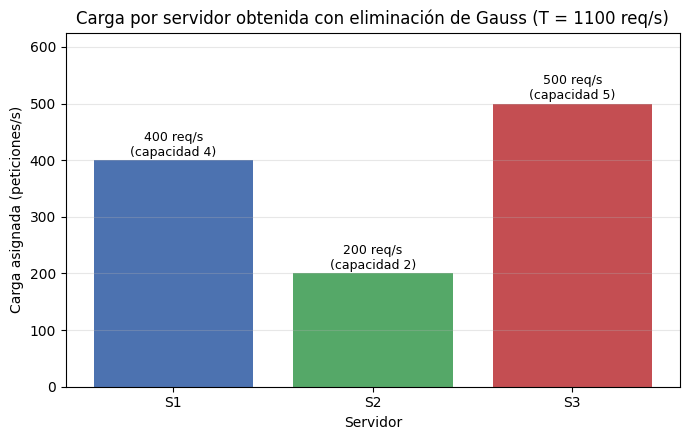

In [16]:
# Celda E — Balance de carga con 3 servidores (capacidades 4, 2 y 5; T = 1100 req/s)
from src.aplicaciones import sistema_balance_carga, balancear_carga

pesos = [4, 2, 5]
total = 1100
A, b = sistema_balance_carga(total, pesos)
resultado = balancear_carga(total, pesos)

print("Matriz de coeficientes A:\n", A)
print("Vector b:", b)
print()
print(resultado)
print()
print(f"{'Servidor':<10}{'Capacidad':<11}{'Carga (req/s)':<15}{'% del total'}")
for i, (w, x) in enumerate(zip(pesos, resultado.solucion), start=1):
    print(f"S{i:<9}{w:<11}{x:<15.1f}{100 * x / total:.1f} %")

cmp = comparar_con_numpy(A, b)
print("\nVerificación contra numpy.linalg.solve:", cmp["detalle"])
assert cmp["coincide"]

fig, ax = plt.subplots(figsize=(7, 4.5))
nombres = [f"S{i}" for i in range(1, len(pesos) + 1)]
barras = ax.bar(nombres, resultado.solucion, color=["#4C72B0", "#55A868", "#C44E52"])
for barra, w in zip(barras, pesos):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 8,
            f"{barra.get_height():.0f} req/s\n(capacidad {w})", ha="center", fontsize=9)
ax.set_xlabel("Servidor")
ax.set_ylabel("Carga asignada (peticiones/s)")
ax.set_title("Carga por servidor obtenida con eliminación de Gauss (T = 1100 req/s)")
ax.set_ylim(0, max(resultado.solucion) * 1.25)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Celda F — Variantes del modelo: 4 servidores, política incompleta y requisitos contradictorios
# (a) 4 servidores (sistema 4x4)
pesos4 = [3, 2, 1, 4]
A4, b4 = sistema_balance_carga(1000, pesos4)
r4 = balancear_carga(1000, pesos4)
print("(a) 4 servidores, capacidades", pesos4)
print(r4)
print("   Verificación NumPy:", comparar_con_numpy(A4, b4)["detalle"])

# (b) Política incompleta: se omite la regla del último servidor -> infinitas soluciones
A_inc, b_inc = A[:-1], b[:-1]
r_inc = eliminacion_gauss(A_inc, b_inc)
print("\n(b) Política incompleta (3 servidores, 2 ecuaciones)")
print(r_inc)
print("   Ejemplo con t1 = 300:", r_inc.solucion_para([300.0]))

# (c) Requisitos contradictorios: se exige además que el total sea 900 req/s
A_con = np.vstack([A, np.ones(3)])
b_con = np.append(b, 900.0)
r_con = eliminacion_gauss(A_con, b_con)
print("\n(c) Requisitos contradictorios (total = 1100 y total = 900)")
print(r_con)

# (d) Sin demanda (sistema homogéneo): solo la solución trivial
print("\n(d) Sin demanda (T = 0)")
print(balancear_carga(0, pesos))

(a) 4 servidores, capacidades [3, 2, 1, 4]
Clasificación: Compatible determinado (solución única)
rango(A) = 4, rango([A|b]) = 4, incógnitas = 4
Tipo: no homogéneo
x1 = 300
x2 = 200
x3 = 100
x4 = 400
   Verificación NumPy: Error máximo |x_Gauss - x_NumPy| = 0.00e+00

(b) Política incompleta (3 servidores, 2 ecuaciones)
Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 3
Tipo: no homogéneo
Solución general (1 parámetro(s) libre(s)):
x1 = 2200/3 - 2/3·t1
x2 = 1100/3 - 1/3·t1
x3 = t1  (variable libre)
   Ejemplo con t1 = 300: [533.33333333 266.66666667 300.        ]

(c) Requisitos contradictorios (total = 1100 y total = 900)
Clasificación: Incompatible (sin solución)
rango(A) = 3, rango([A|b]) = 4, incógnitas = 3
Tipo: no homogéneo
No existe ningún vector x que satisfaga Ax = b.

(d) Sin demanda (T = 0)
Clasificación: Compatible determinado (solución única)
rango(A) = 3, rango([A|b]) = 3, incógnitas = 3
Tipo: homogéneo
x1 = 0
x2 =

## Celda G (Markdown) — Sistema homogéneo aplicado: circulación de tráfico en una red

En una red de tres enrutadores sin tráfico externo, el tráfico que entra a cada nodo debe ser igual al que sale. Con los enlaces $f_1:R_1\to R_2$, $f_2:R_2\to R_3$, $f_3:R_3\to R_1$ y $f_4:R_1\to R_3$ se obtiene un sistema **homogéneo** de rango 2 con cuatro incógnitas, por lo que existen infinitas circulaciones posibles:

$$
\begin{cases}
f_3 - f_1 - f_4 = 0 & (R_1)\\
f_1 - f_2 = 0 & (R_2)\\
f_2 + f_4 - f_3 = 0 & (R_3)
\end{cases}
$$

In [18]:
# Celda H — Resolución de la red de enrutadores
from src.aplicaciones import sistema_flujo_red, analizar_flujo_red

A_red, b_red = sistema_flujo_red()
r_red = analizar_flujo_red()
print("Matriz de conservación A:\n", A_red)
print()
print(r_red)
print()
print("Ejemplo físico (t1 = 5, t2 = 2) -> f =", r_red.solucion_para([5, 2]))
print("Comprobación A·f = 0:", np.allclose(A_red @ r_red.solucion_para([5, 2]), 0))
print("Verificación NumPy:", comparar_con_numpy(A_red, b_red)["detalle"])
print("\nNota: para que los flujos sean físicamente válidos (f ≥ 0) se requiere t1 ≥ t2 ≥ 0.")

Matriz de conservación A:
 [[-1.  0.  1. -1.]
 [ 1. -1.  0.  0.]
 [ 0.  1. -1.  1.]]

Clasificación: Compatible indeterminado (infinitas soluciones)
rango(A) = 2, rango([A|b]) = 2, incógnitas = 4
Tipo: homogéneo
Solución general (2 parámetro(s) libre(s)):
x1 = t1 - t2
x2 = t1 - t2
x3 = t1  (variable libre)
x4 = t2  (variable libre)

Ejemplo físico (t1 = 5, t2 = 2) -> f = [3. 3. 5. 2.]
Comprobación A·f = 0: True
Verificación NumPy: numpy.linalg.solve no aplica (matriz singular o no cuadrada); rango(A) coincide con NumPy: True; residuo de la solución = 0.00e+00

Nota: para que los flujos sean físicamente válidos (f ≥ 0) se requiere t1 ≥ t2 ≥ 0.


# 4. Transformaciones lineales

## Fundamento teórico

Una transformación lineal es una función que relaciona dos espacios vectoriales y conserva las operaciones de suma de vectores y multiplicación por escalares.

En dos dimensiones, estas transformaciones pueden representarse mediante matrices que modifican la posición de los vectores en el plano.

Algunos ejemplos son:

- **Rotación:** gira un vector respecto al origen.
- **Escalamiento:** modifica su magnitud.
- **Reflexión:** invierte su orientación respecto a un eje.
- **Cizallamiento:** desplaza una coordenada en función de la otra.

Estas transformaciones tienen aplicaciones en gráficos por computadora, animaciones y procesamiento de imágenes.

In [19]:
from src.transformaciones import (
    matriz_rotacion,
    aplicar_transformacion
)

# Vector original
vector = np.array([2, 1])

# Ángulo de rotación
angulo = 45

# Crear matriz de rotación
rotacion = matriz_rotacion(angulo)

# Aplicar transformación
vector_transformado = aplicar_transformacion(rotacion, vector)

print("Vector original:", vector)
print("\nMatriz de rotación:")
print(rotacion)

print("\nVector transformado:")
print(vector_transformado)

Vector original: [2 1]

Matriz de rotación:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

Vector transformado:
[0.70710678 2.12132034]


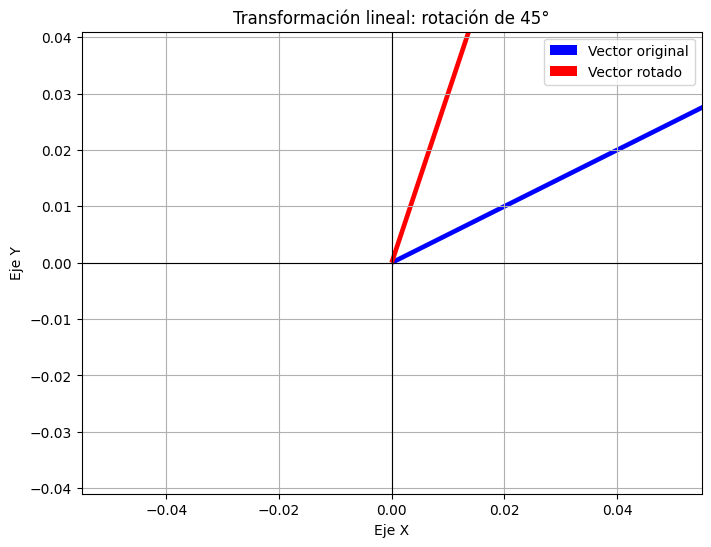

In [20]:
plt.figure(figsize=(8, 6))

plt.quiver(
    0, 0, vector[0], vector[1],
    angles="xy", scale_units="xy", scale=1,
    color="blue", label="Vector original"
)

plt.quiver(
    0, 0,
    vector_transformado[0],
    vector_transformado[1],
    angles="xy", scale_units="xy", scale=1,
    color="red", label="Vector rotado"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

plt.xlim(-1, 3)
plt.ylim(-1, 3)
plt.grid(True)
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.title("Transformación lineal: rotación de 45°")
plt.legend()
plt.axis("equal")
plt.show()

# 4.1 Transformaciones 2D con coordenadas homogéneas

Una traslación no es una transformación lineal en R², porque no deja fijo el origen. Al escribir cada punto como $[x, y, 1]^T$, la traslación se representa con una matriz de 3×3 de la forma

$$\begin{bmatrix} A & \vec{t} \\ \vec{0}^T & 1 \end{bmatrix}$$

donde $A$ es la parte lineal (2×2) y $\vec{t}$ es el vector de traslación. De este modo, rotación, escalamiento, reflexión, cizallamiento y traslación se aplican y se componen con la misma operación: el producto de matrices.

En esta sección las transformaciones se aplican a tres polígonos (un triángulo, un cuadrado y un sprite en forma de flecha). Para cada caso se muestra la figura original frente a la transformada, la matriz utilizada, el determinante de la parte lineal y la verificación de la conservación del área y de las longitudes.

In [21]:
import numpy as np
from src.transformaciones import (
    matriz_traslacion, rotacion_homogenea, escalamiento_homogeneo,
    reflexion_homogenea, cizallamiento_homogeneo, rotacion_alrededor_de_punto,
    crear_triangulo, crear_cuadrado, crear_sprite,
    aplicar_homogenea, analizar_transformacion, verificar_orden_importa,
    componer_transformaciones, graficar_poligono_transformado
)

np.set_printoptions(precision=3, suppress=True)

T = matriz_traslacion(2, 1)
print("Matriz de traslación T(2, 1):\n", T)

triangulo = crear_triangulo()
print("\nVértices originales A, B, C:\n", triangulo)
print("\nVértices trasladados:\n", aplicar_homogenea(T, triangulo))

Matriz de traslación T(2, 1):
 [[1. 0. 2.]
 [0. 1. 1.]
 [0. 0. 1.]]

Vértices originales A, B, C:
 [[1. 1.]
 [5. 1.]
 [3. 4.]]

Vértices trasladados:
 [[3. 2.]
 [7. 2.]
 [5. 5.]]


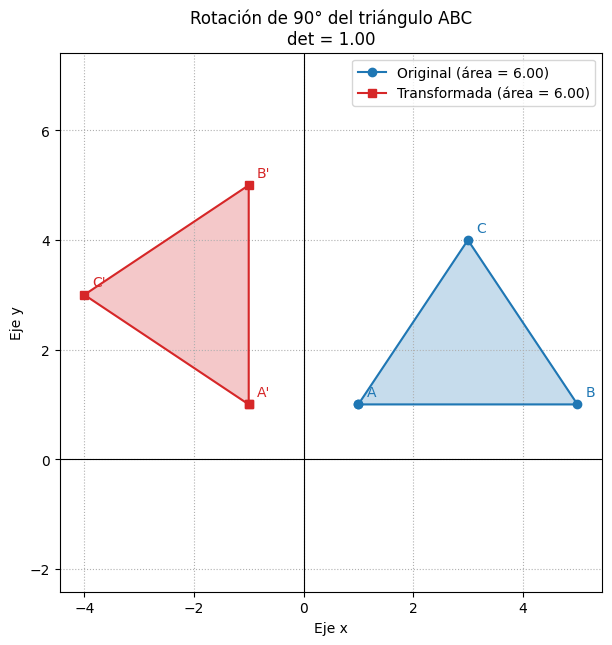

In [22]:
# Figura: rotación de 90° del triángulo
res = graficar_poligono_transformado(
    rotacion_homogenea(90), triangulo,
    titulo="Rotación de 90° del triángulo ABC",
    guardar_en="figura_rotacion_triangulo.png")

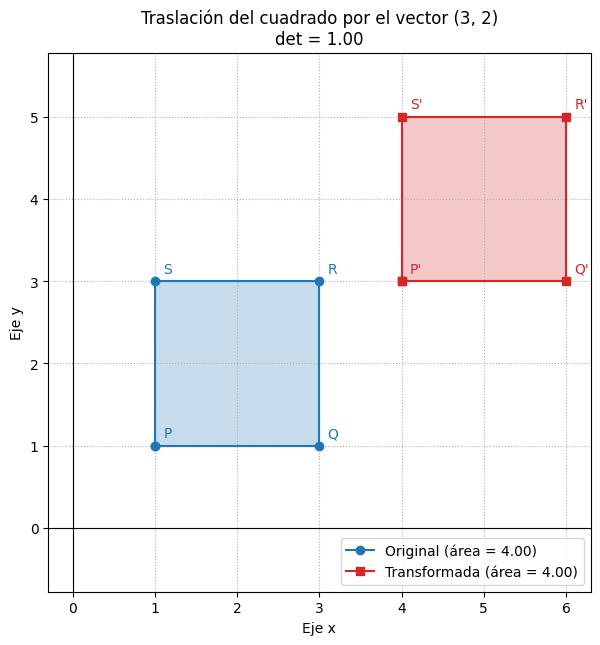

In [23]:
# Figura: traslación del cuadrado
cuadrado = crear_cuadrado()
res = graficar_poligono_transformado(
    matriz_traslacion(3, 2), cuadrado,
    titulo="Traslación del cuadrado por el vector (3, 2)",
    etiquetas=["P", "Q", "R", "S"],
    guardar_en="figura_traslacion_cuadrado.png")

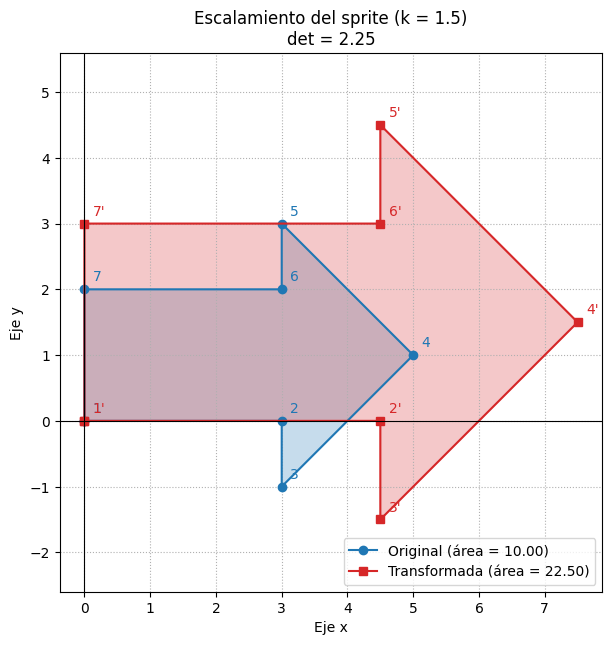

In [24]:
# Figura: escalamiento del sprite
sprite = crear_sprite()
res = graficar_poligono_transformado(
    escalamiento_homogeneo(1.5, 1.5), sprite,
    titulo="Escalamiento del sprite (k = 1.5)",
    etiquetas=[str(i + 1) for i in range(len(sprite))],
    guardar_en="figura_escalamiento_sprite.png")

In [25]:
# Tabla: determinante y conservación de propiedades
import pandas as pd

casos = {
    "Rotación 90°": (rotacion_homogenea(90), triangulo),
    "Escalamiento k = 2": (escalamiento_homogeneo(2, 2), triangulo),
    "Reflexión en x": (reflexion_homogenea("x"), triangulo),
    "Cizallamiento kx = 1": (cizallamiento_homogeneo(kx=1), cuadrado),
    "Traslación (2, 1)": (matriz_traslacion(2, 1), cuadrado),
    "Escalamiento (2, 3)": (escalamiento_homogeneo(2, 3), sprite),
}

filas = []
for nombre, (M, figura) in casos.items():
    r = analizar_transformacion(M, figura)
    filas.append({
        "Transformación": nombre,
        "det(A)": round(r["determinante"], 3),
        "Área original": round(r["area_original"], 3),
        "Área transformada": round(r["area_transformada"], 3),
        "¿Conserva área?": "Sí" if r["conserva_area"] else "No",
        "¿Conserva longitudes?": "Sí" if r["conserva_longitudes"] else "No",
    })

tabla = pd.DataFrame(filas)
print(tabla.to_string(index=False))

      Transformación  det(A)  Área original  Área transformada ¿Conserva área? ¿Conserva longitudes?
        Rotación 90°     1.0            6.0                6.0              Sí                    Sí
  Escalamiento k = 2     4.0            6.0               24.0              No                    No
      Reflexión en x    -1.0            6.0                6.0              Sí                    Sí
Cizallamiento kx = 1     1.0            4.0                4.0              Sí                    No
   Traslación (2, 1)     1.0            4.0                4.0              Sí                    Sí
 Escalamiento (2, 3)     6.0           10.0               60.0              No                    No


T·R (primero rota, después traslada):
 [[ 0. -1.  2.]
 [ 1.  0.  1.]
 [ 0.  0.  1.]]

R·T (primero traslada, después rota):
 [[ 0. -1. -1.]
 [ 1.  0.  2.]
 [ 0.  0.  1.]]

¿T·R es distinta de R·T? True

Triángulo con T·R:
 [[ 1.  2.]
 [ 1.  6.]
 [-2.  4.]]

Triángulo con R·T:
 [[-2.  3.]
 [-2.  7.]
 [-5.  5.]]


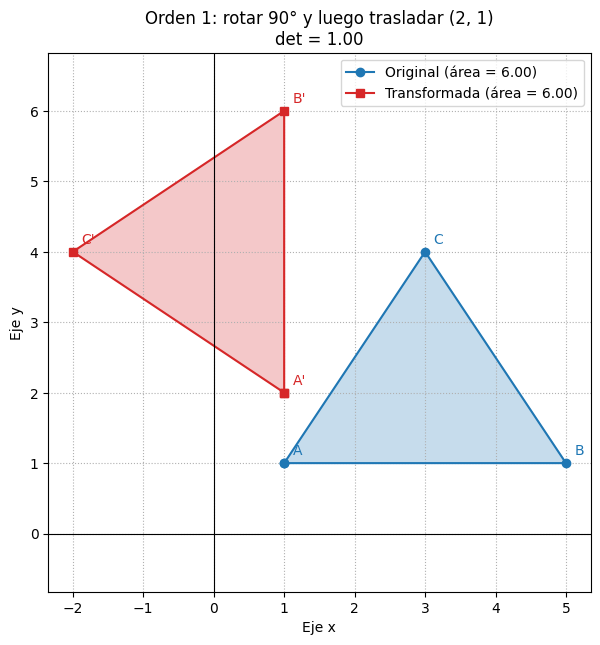

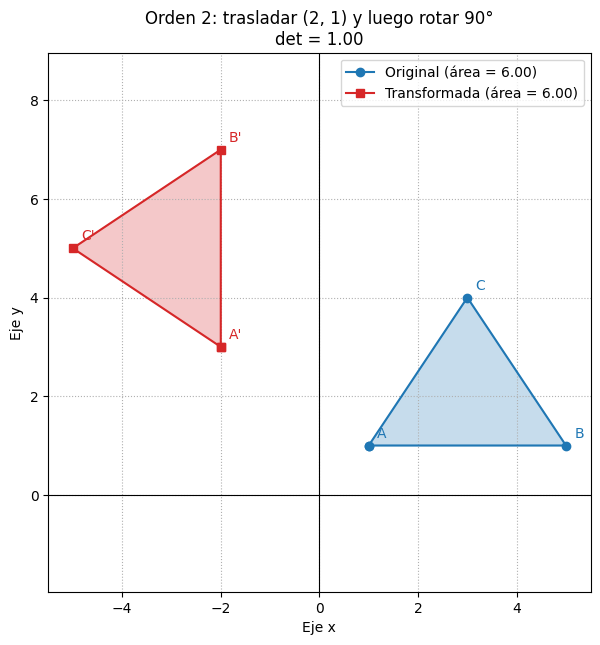

{'transformado': array([[-2.,  3.],
        [-2.,  7.],
        [-5.,  5.]]),
 'determinante': 1.0,
 'determinante_3x3': 1.0,
 'area_original': 6.0,
 'area_transformada': 6.0,
 'razon_area': 1.0,
 'conserva_area': True,
 'conserva_longitudes': True,
 'lados_original': array([4.   , 3.606, 3.606]),
 'lados_transformado': array([4.   , 3.606, 3.606])}

In [26]:
# Composición y comprobación de que el orden importa (AB ≠ BA)
R = rotacion_homogenea(90)
AB, BA, distintas = verificar_orden_importa(T, R)

print("T·R (primero rota, después traslada):\n", AB)
print("\nR·T (primero traslada, después rota):\n", BA)
print("\n¿T·R es distinta de R·T?", distintas)

print("\nTriángulo con T·R:\n", aplicar_homogenea(AB, triangulo))
print("\nTriángulo con R·T:\n", aplicar_homogenea(BA, triangulo))

graficar_poligono_transformado(AB, triangulo,
    titulo="Orden 1: rotar 90° y luego trasladar (2, 1)",
    guardar_en="figura_orden_1.png")
graficar_poligono_transformado(BA, triangulo,
    titulo="Orden 2: trasladar (2, 1) y luego rotar 90°",
    guardar_en="figura_orden_2.png")

Matriz compuesta (primero rota 45°, luego escala ×2):
 [[ 1.414 -1.414  0.   ]
 [ 1.414  1.414  0.   ]
 [ 0.     0.     1.   ]]


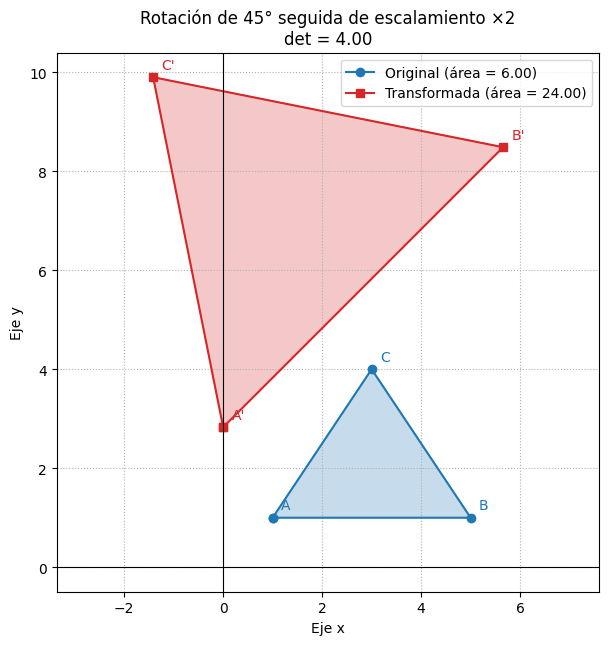

det = 4.0 | razón de áreas = 4.0


In [27]:
# Composición de dos transformaciones: rotar 45° y luego escalar ×2
compuesta = componer_transformaciones(rotacion_homogenea(45), escalamiento_homogeneo(2, 2))
print("Matriz compuesta (primero rota 45°, luego escala ×2):\n", compuesta)
res = graficar_poligono_transformado(compuesta, triangulo,
        titulo="Rotación de 45° seguida de escalamiento ×2",
        guardar_en="figura_composicion.png")
print("det =", round(res["determinante"], 3), "| razón de áreas =", round(res["razon_area"], 3))

# 5. Espacios vectoriales y bases

## Fundamento teórico

Un espacio vectorial es un conjunto de vectores que cumple determinadas propiedades algebraicas bajo las operaciones de suma y multiplicación por escalares.

Dentro de este concepto encontramos:

- **Combinación lineal:** expresión formada mediante la suma de vectores multiplicados por escalares.
- **Independencia lineal:** un conjunto de vectores es linealmente independiente cuando ninguno puede expresarse como combinación lineal de los demás.
- **Base:** conjunto de vectores linealmente independientes que generan todo el espacio.
- **Dimensión:** cantidad de vectores que contiene una base del espacio.
- **Espacio nulo:** conjunto de vectores $\vec{x}$ tales que $A\vec{x}=\vec{0}$.
- **Espacio columna:** conjunto de todas las combinaciones lineales de las columnas de una matriz $A$.

Estos conceptos permiten estudiar la estructura de los espacios y simplificar problemas matemáticos.

In [28]:
from src.espacios_vectoriales import (
    calcular_dimension,
    obtener_base,
    verificar_independencia
)

print("Módulo de espacios vectoriales importado correctamente.")

# Conjunto de vectores
generadores = [
    [1, 0],
    [0, 1]
]

dimension = calcular_dimension(generadores)
base = obtener_base(generadores)
independientes = verificar_independencia(generadores)

print("Vectores generadores:")
print(np.array(generadores))

print("\nDimensión del espacio:", dimension)
print("\nBase del espacio:")
print(base)

print("\n¿Son linealmente independientes?", independientes)

Módulo de espacios vectoriales importado correctamente.
Vectores generadores:
[[1 0]
 [0 1]]

Dimensión del espacio: 2

Base del espacio:
[[1. 0.]
 [0. 1.]]

¿Son linealmente independientes? True


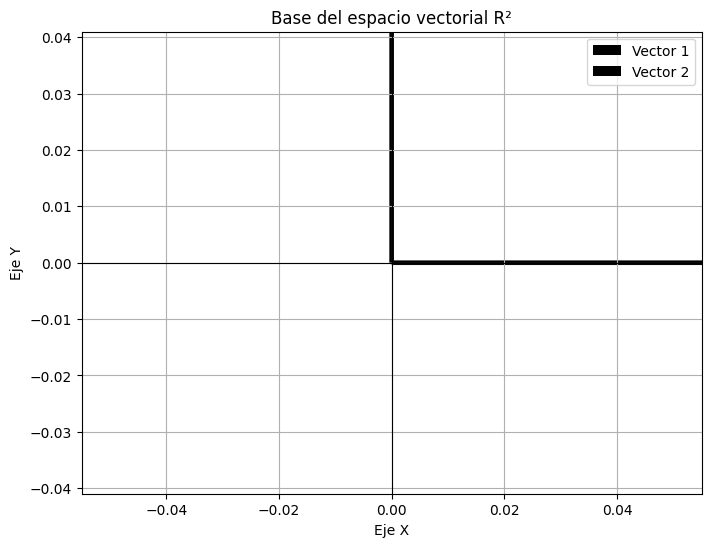

In [29]:
plt.figure(figsize=(8, 6))

for i, vector in enumerate(generadores):
    plt.quiver(
        0, 0, vector[0], vector[1],
        angles="xy", scale_units="xy", scale=1,
        label=f"Vector {i + 1}"
    )

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

plt.xlim(-1, 2)
plt.ylim(-1, 2)
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.title("Base del espacio vectorial R²")
plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()

## Espacio nulo y espacio columna

Dada una matriz $A$ de tamaño $m\times n$, dos subespacios describen por completo lo que hace la transformación $\vec{x}\mapsto A\vec{x}$:

- **Espacio nulo** $N(A)=\{\vec{x}\in\mathbb{R}^n : A\vec{x}=\vec{0}\}$: las entradas que $A$ envía al origen. Es el conjunto solución del sistema homogéneo $A\vec{x}=\vec{0}$, por lo que se calcula con la eliminación de Gauss: cada variable libre aporta un vector de la base. Su dimensión se llama **nulidad**.
- **Espacio columna** $C(A)=\{A\vec{x} : \vec{x}\in\mathbb{R}^n\}\subseteq\mathbb{R}^m$: todas las salidas posibles, es decir, el espacio generado por las columnas de $A$. Una base está formada por las columnas de $A$ que quedan como pivotes tras la eliminación. Su dimensión es el **rango**.

Ambos se relacionan mediante el **teorema rango-nulidad**:

$$\operatorname{rango}(A)+\operatorname{nulidad}(A)=n$$

Además, $A\vec{x}=\vec{b}$ tiene solución si y solo si $\vec{b}\in C(A)$, lo que conecta este módulo con la clasificación de sistemas de la sección anterior.

In [30]:
# Espacio nulo y espacio columna de una matriz 3x4 (la fila 3 es la suma de las filas 1 y 2)
from src.espacios_vectoriales import (
    espacio_nulo,
    espacio_columna,
    verificar_rango_nulidad,
    pertenece_al_espacio
)
from src.sistemas import eliminacion_gauss

A_esp = np.array([
    [1, 2, 1, 3],
    [2, 4, 0, 2],
    [3, 6, 1, 5]
], dtype=float)

base_nulo = espacio_nulo(A_esp)
base_columna = espacio_columna(A_esp)

print("Matriz A (3x4):")
print(A_esp)

print("\nBase del espacio columna C(A) (columnas pivote de A):")
for k, v in enumerate(base_columna, start=1):
    print(f"  c{k} = {v}")

print("\nBase del espacio nulo N(A) (una por cada variable libre):")
for k, v in enumerate(base_nulo, start=1):
    print(f"  n{k} = {np.round(v, 6) + 0.0}")

print("\nComprobación A·n = 0 para cada vector de la base de N(A):")
print(np.round(A_esp @ base_nulo.T, 10) + 0.0)

rn = verificar_rango_nulidad(A_esp)
print(f"\nTeorema rango-nulidad: rango = {rn['rango']}, nulidad = {rn['nulidad']}, "
      f"n = {rn['columnas']} -> {rn['rango']} + {rn['nulidad']} = {rn['rango'] + rn['nulidad']}")

# Relación con los sistemas: Ax = b es compatible exactamente cuando b está en C(A)
b_dentro = A_esp @ np.array([1, 1, 1, 1])   # = (7, 8, 15), pertenece a C(A)
b_fuera = np.array([1, 0, 0])               # no cumple b3 = b1 + b2

for nombre, b in [("b dentro de C(A)", b_dentro), ("b fuera de C(A)", b_fuera)]:
    en_columna = pertenece_al_espacio(b, base_columna)
    clasif = eliminacion_gauss(A_esp, b).clasificacion.split(" (")[0]
    print(f"\n{nombre}: b = {b}  ->  ¿b en C(A)? {en_columna}  |  Sistema Ax = b: {clasif}")
    assert en_columna == (clasif != "Incompatible")

assert rn["cumple"]
assert np.allclose(A_esp @ base_nulo.T, 0)

Matriz A (3x4):
[[1. 2. 1. 3.]
 [2. 4. 0. 2.]
 [3. 6. 1. 5.]]

Base del espacio columna C(A) (columnas pivote de A):
  c1 = [1. 2. 3.]
  c2 = [1. 0. 1.]

Base del espacio nulo N(A) (una por cada variable libre):
  n1 = [-2.  1.  0.  0.]
  n2 = [-1.  0. -2.  1.]

Comprobación A·n = 0 para cada vector de la base de N(A):
[[0. 0.]
 [0. 0.]
 [0. 0.]]

Teorema rango-nulidad: rango = 2, nulidad = 2, n = 4 -> 2 + 2 = 4

b dentro de C(A): b = [ 7.  8. 15.]  ->  ¿b en C(A)? True  |  Sistema Ax = b: Compatible indeterminado

b fuera de C(A): b = [1 0 0]  ->  ¿b en C(A)? False  |  Sistema Ax = b: Incompatible


Matriz A:
[[1. 2.]
 [3. 6.]]
Base de N(A): [[-2.  1.]]
Base de C(A): [[1. 3.]]
Rango + nulidad: {'rango': 1, 'nulidad': 1, 'columnas': 2, 'cumple': True}


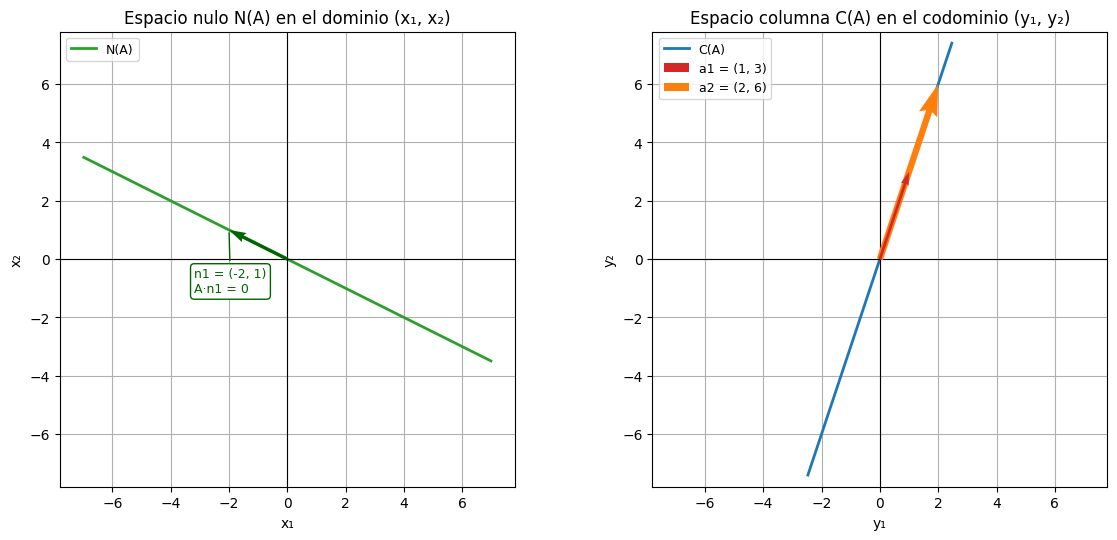

In [31]:
# Representación gráfica de N(A) y C(A) para una matriz 2x2 de rango 1
from src.espacios_vectoriales import graficar_espacio_nulo_y_columna

A_graf = np.array([
    [1, 2],
    [3, 6]
], dtype=float)

print("Matriz A:")
print(A_graf)
print("Base de N(A):", np.round(espacio_nulo(A_graf), 6) + 0.0)
print("Base de C(A):", espacio_columna(A_graf))
print("Rango + nulidad:", verificar_rango_nulidad(A_graf))

graficar_espacio_nulo_y_columna(A_graf, guardar_en="figura_espacio_nulo_columna.png")

# 6. Gamificación: el gran reto algebraico

## Fundamento y mecánica del juego

La gamificación incorpora elementos propios de los juegos en el proceso de aprendizaje para fomentar la participación, la práctica y la evaluación de los conocimientos adquiridos.

En Transforma-Tec se implementa un recorrido progresivo de cinco niveles, con tres retos aleatorios por nivel (15 retos en total). La selección de los retos es reproducible mediante una semilla fija.

### Niveles

1. **Vectores:** norma, producto punto y operaciones vectoriales.
2. **Matrices:** determinante, traza y elementos matriciales.
3. **Sistemas de ecuaciones:** solución de sistemas y clasificación.
4. **Transformaciones 2D:** escalamiento, traslación y rotación.
5. **Transformaciones compuestas:** coordenadas homogéneas y orden de composición.

### Reglas

- Cada reto correcto otorga 10 puntos.
- Cada respuesta incorrecta descuenta una vida.
- La partida comienza con tres vidas.
- Para superar un nivel se necesitan al menos dos respuestas correctas de sus tres retos (20 puntos).
- Al superar un nivel se obtiene su insignia y se desbloquea el siguiente.
- La partida termina al completar los cinco niveles o al quedarse sin vidas. Si no se alcanza el puntaje mínimo de un nivel, el recorrido se cierra.
- La demo utiliza controles interactivos de `ipywidgets` y muestra el puntaje, las vidas, la retroalimentación y la tabla de progreso.

La semilla predeterminada es `2026`, por lo que los mismos retos se pueden reproducir durante las pruebas y la demostración.


In [32]:
from src.gamificacion import (
    generar_retos,
    evaluar_reto,
    PartidaGamificada,
    iniciar_juego
)

print("Sistema de gamificación progresiva importado correctamente.")


Sistema de gamificación progresiva importado correctamente.


In [ ]:
# DEMO INTERACTIVA
# Ejecuta esta celda en Google Colab y responde los retos desde el campo de texto.
# La semilla fija permite reproducir la misma selección de retos.
partida_demo = iniciar_juego(seed=2026)

In [33]:
# Verificación de la generación reproducible de retos

retos_1 = generar_retos(seed=2026)
retos_2 = generar_retos(seed=2026)

assert retos_1 == retos_2
assert len(retos_1) == 5
assert all(len(nivel["retos"]) == 3 for nivel in retos_1)

print("Niveles generados:", len(retos_1))
print("Retos generados:", sum(len(n["retos"]) for n in retos_1))
print("La semilla 2026 reproduce exactamente los mismos retos.")


Niveles generados: 5
Retos generados: 15
La semilla 2026 reproduce exactamente los mismos retos.


In [34]:
# Prueba automática integral de la gamificación

# 1. Evaluación numérica y textual
assert evaluar_reto(
    {"tipo": "numero", "respuesta": 5, "tolerancia": 1e-6}, "5"
)
assert evaluar_reto(
    {"tipo": "texto", "respuesta": "Sí"}, "si"
)
assert not evaluar_reto(
    {"tipo": "numero", "respuesta": 5, "tolerancia": 1e-6}, "8"
)

# 2. Simulación de una partida perfecta: 15 respuestas correctas
partida_prueba = PartidaGamificada(seed=2026)
while not partida_prueba.finalizada:
    reto = partida_prueba.niveles[partida_prueba.nivel_actual]["retos"][partida_prueba.reto_actual]
    partida_prueba.responder(str(reto["respuesta"]))

resumen_prueba = partida_prueba.resumen()
assert resumen_prueba["estado"] == "Completada"
assert resumen_prueba["correctas"] == 15
assert resumen_prueba["incorrectas"] == 0
assert resumen_prueba["puntaje"] == 150
assert len(resumen_prueba["insignias"]) == 5

# 3. Verificación de pérdida de vidas y finalización
partida_vidas = PartidaGamificada(seed=2026)
for _ in range(3):
    partida_vidas.responder("respuesta_incorrecta")
assert partida_vidas.finalizada
assert partida_vidas.vidas == 0
assert len(partida_vidas.insignias) == 0

print("Prueba integral superada.")
print("Resultado perfecto:", resumen_prueba)
print("\nTabla de progreso de la partida perfecta:")
try:
    import pandas as pd
    display(pd.DataFrame(partida_prueba.tabla_progreso()))
except ImportError:
    for fila in partida_prueba.tabla_progreso():
        print(fila)


Prueba integral superada.
Resultado perfecto: {'puntaje': 150, 'vidas_restantes': 3, 'retos_respondidos': 15, 'correctas': 15, 'incorrectas': 0, 'insignias': ['Explorador Vectorial', 'Arquitecto de Matrices', 'Maestro de Gauss', 'Rotador Experto', 'Arquitecto Homogéneo'], 'estado': 'Completada'}

Tabla de progreso de la partida perfecta:


,Nivel,Tema,Retos respondidos,Correctas,Puntos,Estado,Insignia
0,1,Vectores,3,3,30,Superado,Explorador Vectorial
1,2,Matrices,3,3,30,Superado,Arquitecto de Matrices
2,3,Sistemas de ecuaciones,3,3,30,Superado,Maestro de Gauss
3,4,Transformaciones 2D,3,3,30,Superado,Rotador Experto
4,5,Transformaciones compuestas,3,3,30,Superado,Arquitecto Homogéneo


# 7. Conclusiones

El desarrollo de **Transforma-Tec: El Gran Reto Final** permitió aplicar los conceptos fundamentales del álgebra lineal mediante ejercicios prácticos implementados en Python. A lo largo del proyecto se trabajó con operaciones entre vectores y matrices, resolución de sistemas de ecuaciones lineales, transformaciones lineales y análisis de espacios vectoriales, relacionando los fundamentos teóricos con resultados numéricos y representaciones gráficas.

La organización del código en módulos independientes facilitó la separación de responsabilidades y permitió reutilizar las funciones desarrolladas. Además, las pruebas ejecutadas ayudaron a comprobar el comportamiento de las operaciones y la solución de los ejercicios, incluyendo la verificación del sistema de ecuaciones mediante sustitución.

Como complemento, el módulo de gamificación incorpora cinco niveles progresivos y quince retos generados de forma reproducible mediante una semilla fija. El sistema administra vidas, puntajes, insignias, retroalimentación y desbloqueo de niveles, e incluye una demo interactiva con ipywidgets. Las pruebas automáticas simulan una partida perfecta y un escenario de agotamiento de vidas para verificar las reglas implementadas.

En conclusión, Transforma-Tec reúne teoría, programación, pruebas y recursos visuales en una herramienta de apoyo para practicar álgebra lineal. El proyecto permitió fortalecer la comprensión de los conceptos matemáticos y su aplicación mediante soluciones computacionales, así como la organización y validación de un desarrollo modular en Python.
